# 06 - Explaining the final model with SHAP

**Goal:** understand which features the final model (LightGBM, trained on 2003-2016) relies on. The explanations are computed for the test-year commits (2017); this is descriptive only and changes nothing in the model, the thresholds or the results.

**How to read SHAP values:** for LightGBM they are in log-odds units. The model score of a commit = a baseline (the average score) + the sum of the SHAP values of its 12 features. A positive value pushes the commit towards "bug-inducing", a negative value towards "clean". Correlated features share their importance, so results are also shown by feature group.

In [1]:
import sys
sys.path.append("..")

import json
import numpy as np
import pandas as pd
import shap

from src.data.split import load_data, time_split, FEATURES, LABEL
from src.models.builders import make_lightgbm

df = load_data()
train, validation, test, late = time_split(df)

with open("../results/04_lightgbm_params.json") as f:
    params = json.load(f)

dev = pd.concat([train, validation])
model = make_lightgbm(**params).fit(dev[FEATURES], dev[LABEL])

## 1. Compute the SHAP values

**Goal:** get one SHAP value per feature for every test commit, and check the rule "baseline + sum of SHAP values = model score". The printed number should be practically zero. A harmless warning about the output format may appear.

In [2]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(test[FEATURES])
if isinstance(shap_values, list):
    shap_values = shap_values[1]
if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]
shap_df = pd.DataFrame(shap_values, columns=FEATURES, index=test.index)

base = float(np.ravel(explainer.expected_value)[-1])
raw = model.predict_proba(test[FEATURES], raw_score=True)
print("largest gap between baseline + SHAP sum and the model score:", float(np.abs(shap_df.sum(axis=1) + base - raw).max()))

largest gap between baseline + SHAP sum and the model score: 4.707345624410664e-14


d:\Courses\commit-wise\.venv\Lib\site-packages\shap\explainers\_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


## 2. Global importance

**Goal:** rank the features by their average effect on the model score. The bar for a feature is the mean of the absolute SHAP values over all test commits (the direction is ignored here; it is studied for single commits in the next step).

la       0.966
age      0.210
arexp    0.203
asexp    0.174
nuc      0.174
aexp     0.155
ndev     0.151
nf       0.148
ld       0.132
nd       0.077
ns       0.059
ent      0.057
dtype: float64

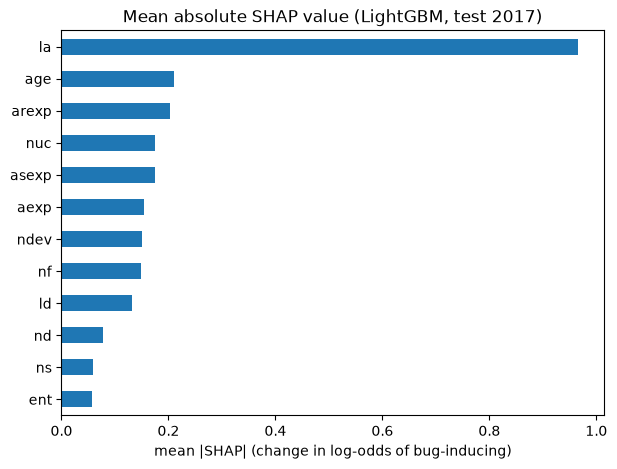

In [3]:
importance = shap_df.abs().mean().sort_values()
ax = importance.plot(kind="barh", figsize=(7, 5), title="Mean absolute SHAP value (LightGBM, test 2017)")
ax.set_xlabel("mean |SHAP| (change in log-odds of bug-inducing)")
ax.figure.savefig("../reports/figures/06_shap_importance.png", dpi=150, bbox_inches="tight")
importance.round(3).sort_values(ascending=False)

## 3. Importance by feature group

**Goal:** because correlated features share importance, add the SHAP values of the features of each group for every commit first, and then take the mean absolute value. Groups (from the EDA): size and spread (`la`, `ld`, `nf`, `nd`, `ns`, `ent`), file history (`ndev`, `age`, `nuc`) and author experience (`aexp`, `arexp`, `asexp`).

size and spread      1.075
file history         0.308
author experience    0.277
dtype: float64

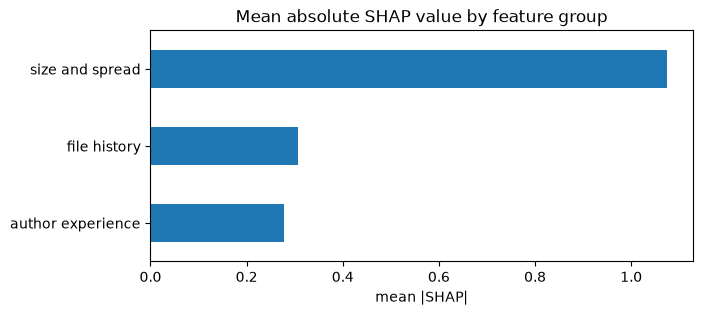

In [4]:
groups = {
    "size and spread": ["la", "ld", "nf", "nd", "ns", "ent"],
    "file history": ["ndev", "age", "nuc"],
    "author experience": ["aexp", "arexp", "asexp"],
}
group_shap = pd.DataFrame({g: shap_df[cols].sum(axis=1) for g, cols in groups.items()})
group_importance = group_shap.abs().mean().sort_values()

ax = group_importance.plot(kind="barh", figsize=(7, 3), title="Mean absolute SHAP value by feature group")
ax.set_xlabel("mean |SHAP|")
ax.figure.savefig("../reports/figures/06_shap_groups.png", dpi=150, bbox_inches="tight")
group_importance.round(3).sort_values(ascending=False)

**Observation**
- The additivity check passed (largest gap about 5e-14), so baseline + sum of SHAP values reproduces the model score. The warning about the output format is harmless.
- One feature dominates: `la` (lines added) has a mean |SHAP| of 0.966, about 4.6 times the next feature (`age`, 0.210). The others lie between 0.06 and 0.21: `arexp` 0.203, `asexp` 0.174, `nuc` 0.174, `aexp` 0.155, `ndev` 0.151, `nf` 0.148, `ld` 0.132, `nd` 0.077, `ns` 0.059, `ent` 0.057.
- By group, size and spread dominates (1.075) against file history (0.308) and author experience (0.277), about 3.5 to 4 times each. Inside the size group `la` carries most of the weight: the six individual importances add up to 1.44 but the group value is 1.08, so the SHAP values of correlated size features partly offset each other within commits.
- Compared with the EDA: `la` was also the strongest single feature there. `nd`, `ns` and `ent` get the lowest importance (0.06-0.08) although they were clearly linked to the label in the correlation analysis, probably because they are highly correlated with other size features (for example `ent` with `nf`, 0.96). `age` is second in importance although its correlation with the label was weak (0.09), which suggests the model uses it in a non-linear way or in interactions (not tested). The order among `aexp`, `arexp` and `asexp` should not be over-read: `aexp` and `arexp` are near duplicates (correlation 0.99), so how they share importance is arbitrary.
- SHAP describes what the model uses, not what causes bugs. The strong role of `la` fits the "size bias in labels" caveat in `docs/threats_to_validity.md` (SZZ labels may favour large changes), so part of it may come from the labeling method.

**Decision:** report importance by feature group in the report and in the dashboard, with `la` as the main single feature, and do not interpret the order of correlated features.

## 4. Explaining single commits

**Goal:** show why the model gave a particular score to three test commits: the highest-risk one, the one closest to the decision threshold (0.66) and the lowest-risk one. For each, the five features with the largest effect are listed with the commit's real value and its SHAP value (positive = towards bug-inducing, negative = towards clean). The label shown is only for information.

In [5]:
proba = model.predict_proba(test[FEATURES])[:, 1]
order = np.argsort(proba)
examples = {
    "highest risk": int(order[-1]),
    "near the threshold (0.66)": int(np.argmin(np.abs(proba - 0.66))),
    "lowest risk": int(order[0]),
}

def explain_commit(position, k=5):
    row = pd.DataFrame({"value": test[FEATURES].iloc[position], "SHAP": shap_df.iloc[position]})
    return row.reindex(row["SHAP"].abs().sort_values(ascending=False).index).head(k)

for label, pos in examples.items():
    print(label, "| probability:", round(proba[pos], 3), "| labeled bug-inducing:", bool(test[LABEL].iloc[pos]))
    print(explain_commit(pos).round(3).to_string())
    print()

highest risk | probability: 0.972 | labeled bug-inducing: True
          value   SHAP
la     6016.000  2.519
nf       50.000  0.583
ns        4.000  0.328
age      26.220  0.281
asexp     0.622  0.190

near the threshold (0.66) | probability: 0.66 | labeled bug-inducing: True
         value   SHAP
la     123.000  0.813
age    391.143 -0.293
asexp    0.000  0.293
aexp     0.000 -0.232
ndev     2.000  0.212

lowest risk | probability: 0.001 | labeled bug-inducing: False
           value   SHAP
la         0.000 -5.241
aexp   12439.000 -0.480
arexp   4224.006 -0.466
ld       535.000 -0.376
asexp    488.000 -0.259



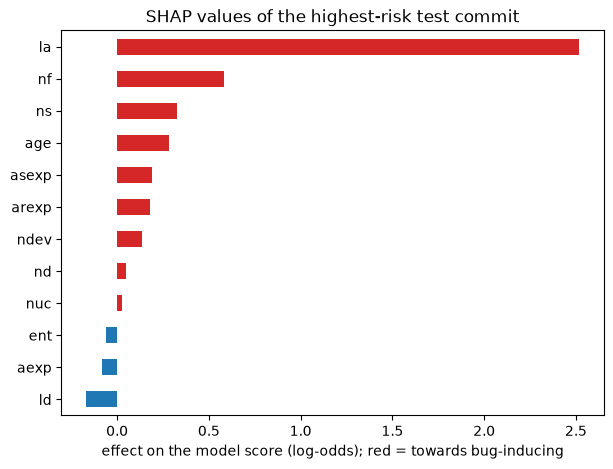

In [6]:
row = shap_df.iloc[examples["highest risk"]].sort_values()
colors = ["tab:red" if v > 0 else "tab:blue" for v in row]
ax = row.plot(kind="barh", color=colors, figsize=(7, 5), title="SHAP values of the highest-risk test commit")
ax.set_xlabel("effect on the model score (log-odds); red = towards bug-inducing")
ax.figure.savefig("../reports/figures/06_shap_example_commit.png", dpi=150, bbox_inches="tight")

In [7]:
export = test[["commit_id", "project", "author_date", LABEL]].copy()
export["probability"] = proba
export["flagged"] = proba >= 0.66
export = pd.concat([export, test[FEATURES].add_prefix("value_"), shap_df.add_prefix("shap_")], axis=1)
export.round(4).to_csv("../results/06_test_explanations.csv", index=False)

with open("../results/06_shap_base_value.json", "w") as f:
    json.dump({"base_value": base}, f)